In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [15]:
I = cv2.imread("image1.jpg", cv2.IMREAD_GRAYSCALE)
st_elem = np.array([[0, 1, 0],
                     [1, 1, 1],
                     [0, 1, 0]], dtype=np.uint8)
I_out = cv2.erode(I, st_elem, iterations=1)
I_out = cv2.dilate(I_out, st_elem, iterations=1)

Text(0.5, 1.0, 'Salida')

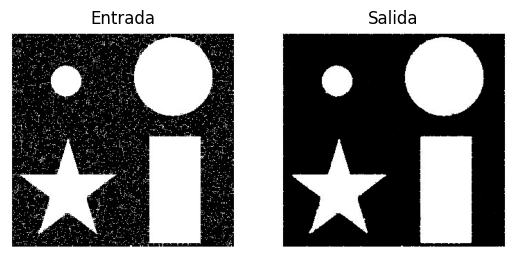

In [16]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(I,cmap='gray')
plt.axis("off")
plt.title("Entrada")
plt.subplot(1, 2, 2)
plt.imshow(I_out,cmap='gray')
plt.axis("off")
plt.title("Salida")

# Ejemplo imagen real

(-0.5, 666.5, 888.5, -0.5)

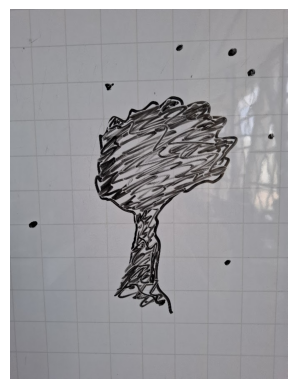

In [2]:
Ibgr = cv2.imread("tablero.jpg")
Irgb = cv2.cvtColor(Ibgr, cv2.COLOR_BGR2RGB)

plt.figure()
plt.imshow(Irgb)
plt.axis("off")

Text(0.5, 1.0, 'Imagen binarizada')

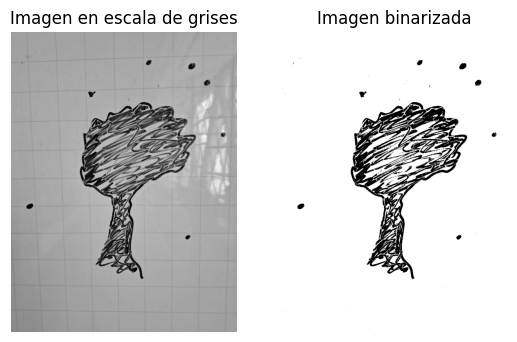

In [3]:
Igray = cv2.cvtColor(Ibgr, cv2.COLOR_BGR2GRAY)
thresh = 110
Ibin = np.zeros_like(Igray)
Ibin[Igray > thresh] = 255
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(Igray, cmap='gray')
plt.axis("off")
plt.title("Imagen en escala de grises")
plt.subplot(1, 2, 2)
plt.imshow(Ibin, cmap='gray')
plt.axis("off")
plt.title("Imagen binarizada")

In [4]:
I_in = 255-Ibin
st_elem = np.array([[0, 1, 0],
                     [1, 1, 1],
                     [0, 1, 0]], dtype=np.uint8)
I_out = cv2.erode(I_in, st_elem, iterations=2)
I_out = cv2.dilate(I_out, st_elem, iterations=28)
I_out = cv2.erode(I_out, st_elem, iterations=35)
I_out = cv2.dilate(I_out, st_elem, iterations=9)

Text(0.5, 1.0, 'Salida')

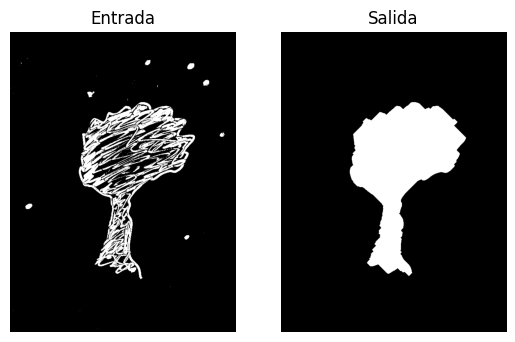

In [5]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(I_in,cmap='gray')
plt.axis("off")
plt.title("Entrada")
plt.subplot(1, 2, 2)
plt.imshow(I_out,cmap='gray')
plt.axis("off")
plt.title("Salida")

In [19]:
I_mask = I_out.copy()

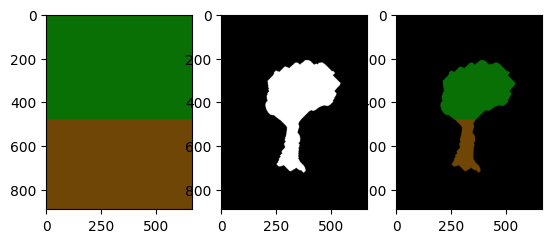

In [21]:
nrow, ncol = I_mask.shape
I_col = np.zeros((nrow, ncol, 3), dtype=np.uint8)
I_col[:480,:,:] = [9, 112, 6]
I_col[480:,:,:] = [112, 70, 7]

I_tree = I_col.copy()
I_tree[I_mask==0] = [0, 0, 0]

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(I_col)

plt.subplot(1, 3, 2)
plt.imshow(I_mask, cmap='gray', vmin=0, vmax=255)

plt.subplot(1, 3, 3)
plt.imshow(I_tree)

(-0.5, 666.5, 888.5, -0.5)

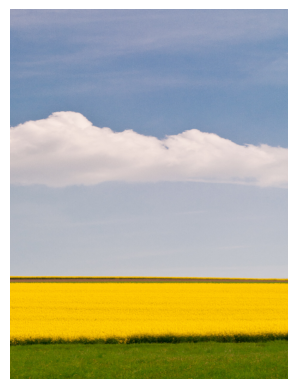

In [30]:
img_fondo = cv2.imread("fondo.jpg")
img_fondo = cv2.cvtColor(img_fondo, cv2.COLOR_BGR2RGB)
img_fondo_rs = cv2.resize(img_fondo[:,3000:,:], (ncol, nrow))

plt.figure()
plt.imshow(img_fondo_rs)
plt.axis("off")

In [31]:
img_fondo_rs.shape

(889, 667, 3)

In [32]:
I_tree.shape

(889, 667, 3)

(-0.5, 666.5, 888.5, -0.5)

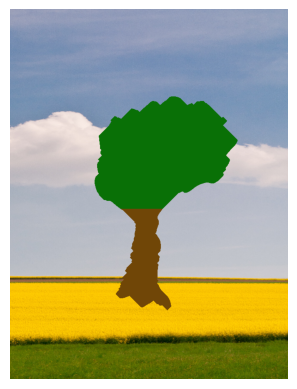

In [33]:
I_tree_fondo = np.zeros_like(I_tree)
I_tree_fondo = np.where(I_tree==0, img_fondo_rs, I_tree)

plt.figure()
plt.imshow(I_tree_fondo)
plt.axis("off")

(-0.5, 666.5, 888.5, -0.5)

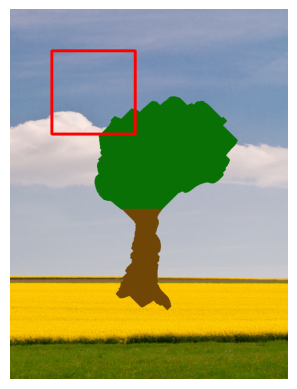

In [34]:
I2 = I_tree_fondo.copy()
x1, y1 = 100, 100
x2, y2 = 300, 300
color = (255, 0, 0)  # Color in RGB
grosor = 5  # Thickness of the rectangle
cv2.rectangle(I2, (x1, y1), (x2, y2), color, grosor)

plt.figure()
plt.imshow(I2)
plt.axis("off")